In [31]:
import multixrank
import os
import pandas as pd
import random
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

In [32]:
CURRENT_DIR = os.getcwd()
CANCER_HALLMARKS_FOLDER = os.path.join(CURRENT_DIR, "../../../../Data/ValidationData/CancerHallmarks")

In [33]:
dico_hallmarks_ids = {
    "01": "TISSUE_INVASION_METASTASIS",
    "02": "REPROGRAMMING_ENERGY_METABOLISM",
    "03": "REPLICATIVE_IMMORTALITY",
    "04": "GENOME_INSTABILITY",
    "05": "RESISTING_CELL_DEATH",
    "06": "EVADING_GROWTH_SUPPRESSORS",
    "07": "EVADING_IMMUNE_DESTRUCTION",
    "08": "SUSTAINED_ANGIOGENESIS",
    "09": "SUSTAINING_PROLIFERATIVE_SIGNALING",
    "10": "TUMOR_PROMOTING_INFLAMMATION"
}

In [34]:
print(dico_hallmarks_ids)
dico_hallmarks_ids_reduced = dico_hallmarks_ids.copy()

{'01': 'TISSUE_INVASION_METASTASIS', '02': 'REPROGRAMMING_ENERGY_METABOLISM', '03': 'REPLICATIVE_IMMORTALITY', '04': 'GENOME_INSTABILITY', '05': 'RESISTING_CELL_DEATH', '06': 'EVADING_GROWTH_SUPPRESSORS', '07': 'EVADING_IMMUNE_DESTRUCTION', '08': 'SUSTAINED_ANGIOGENESIS', '09': 'SUSTAINING_PROLIFERATIVE_SIGNALING', '10': 'TUMOR_PROMOTING_INFLAMMATION'}


In [35]:
print(dico_hallmarks_ids_reduced)
del dico_hallmarks_ids_reduced['02']
del dico_hallmarks_ids_reduced['03']
del dico_hallmarks_ids_reduced['04']
del dico_hallmarks_ids_reduced['05']
del dico_hallmarks_ids_reduced['06']
del dico_hallmarks_ids_reduced['07']
del dico_hallmarks_ids_reduced['08']
del dico_hallmarks_ids_reduced['09']
del dico_hallmarks_ids_reduced['10']
print(dico_hallmarks_ids_reduced)

{'01': 'TISSUE_INVASION_METASTASIS', '02': 'REPROGRAMMING_ENERGY_METABOLISM', '03': 'REPLICATIVE_IMMORTALITY', '04': 'GENOME_INSTABILITY', '05': 'RESISTING_CELL_DEATH', '06': 'EVADING_GROWTH_SUPPRESSORS', '07': 'EVADING_IMMUNE_DESTRUCTION', '08': 'SUSTAINED_ANGIOGENESIS', '09': 'SUSTAINING_PROLIFERATIVE_SIGNALING', '10': 'TUMOR_PROMOTING_INFLAMMATION'}
{'01': 'TISSUE_INVASION_METASTASIS'}


##### 4.3 - On weighted comembershipclique of Reactome with r = 0.7

In [46]:
for hallmark_id, hallmark_name in dico_hallmarks_ids_reduced.items():
    multixrank_obj = multixrank.Multixrank(config=f"../../../../Results/PathwayComembership/10_ValidationRWR_bis/RWRWeightedClique0_7/output_{hallmark_name}/{hallmark_name}_config.yml", wdir=f"../../../../Results/PathwayComembership/10_ValidationRWR_bis/RWRWeightedClique0_7/output_{hallmark_name}")
    ranking_df = multixrank_obj.random_walk_rank()
    multixrank_obj.write_ranking(ranking_df, path=f"../../../../Results/PathwayComembership/10_ValidationRWR_bis/RWRWeightedClique0_7/output_{hallmark_name}")

/home/cbeust/miniconda3/lib/python3.11/site-packages/multixrank/Seed.py:110: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.0020876826722338203' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  seed_score_df.loc[seed_label, layer.key] = multiplex.eta * layer.tau / len(self.multiplex_seed_list2d[multiplex_idx])


##### 4.4 - On unweighted comembership clique of Reactome with r = 0.7

In [47]:
for hallmark_id, hallmark_name in dico_hallmarks_ids_reduced.items():
    multixrank_obj = multixrank.Multixrank(config=f"../../../../Results/PathwayComembership/10_ValidationRWR_bis/RWRUnweightedClique0_7/output_{hallmark_name}/{hallmark_name}_config.yml", wdir=f"../../../../Results/PathwayComembership/10_ValidationRWR_bis/RWRUnweightedClique0_7/output_{hallmark_name}")
    ranking_df = multixrank_obj.random_walk_rank()
    multixrank_obj.write_ranking(ranking_df, path=f"../../../../Results/PathwayComembership/10_ValidationRWR_bis/RWRUnweightedClique0_7/output_{hallmark_name}")

/home/cbeust/miniconda3/lib/python3.11/site-packages/multixrank/Seed.py:110: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.0020876826722338203' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  seed_score_df.loc[seed_label, layer.key] = multiplex.eta * layer.tau / len(self.multiplex_seed_list2d[multiplex_idx])


##### 4.5 - On weighted comembershipclique of Reactome (WITHOUT NSP) with r = 0.7

In [48]:
for hallmark_id, hallmark_name in dico_hallmarks_ids_reduced.items():
    multixrank_obj = multixrank.Multixrank(config=f"../../../../Results/PathwayComembership/10_ValidationRWR_bis/RWRWeightedCliqueNO_NSP_0_7/output_{hallmark_name}/{hallmark_name}_config.yml", wdir=f"../../../../Results/PathwayComembership/10_ValidationRWR_bis/RWRWeightedCliqueNO_NSP_0_7/output_{hallmark_name}")
    ranking_df = multixrank_obj.random_walk_rank()
    multixrank_obj.write_ranking(ranking_df, path=f"../../../../Results/PathwayComembership/10_ValidationRWR_bis/RWRWeightedCliqueNO_NSP_0_7/output_{hallmark_name}")

/home/cbeust/miniconda3/lib/python3.11/site-packages/multixrank/Seed.py:110: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.0020876826722338203' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  seed_score_df.loc[seed_label, layer.key] = multiplex.eta * layer.tau / len(self.multiplex_seed_list2d[multiplex_idx])


##### 4.6 - On weighted comembershipclique of Reactome with COSINE SIMILARITY with r = 0.7

In [49]:
for hallmark_id, hallmark_name in dico_hallmarks_ids_reduced.items():
    multixrank_obj = multixrank.Multixrank(config=f"../../../../Results/PathwayComembership/10_ValidationRWR_bis/RWRWeightedClique_COSINE_0_7/output_{hallmark_name}/{hallmark_name}_config.yml", wdir=f"../../../../Results/PathwayComembership/10_ValidationRWR_bis/RWRWeightedClique_COSINE_0_7/output_{hallmark_name}")
    ranking_df = multixrank_obj.random_walk_rank()
    multixrank_obj.write_ranking(ranking_df, path=f"../../../../Results/PathwayComembership/10_ValidationRWR_bis/RWRWeightedClique_COSINE_0_7/output_{hallmark_name}")

/home/cbeust/miniconda3/lib/python3.11/site-packages/multixrank/Seed.py:110: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.0020876826722338203' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  seed_score_df.loc[seed_label, layer.key] = multiplex.eta * layer.tau / len(self.multiplex_seed_list2d[multiplex_idx])


##### 4.7 - On weighted comembershipclique of Reactome with JACCARD SIMILARITY with r = 0.7

In [51]:
for hallmark_id, hallmark_name in dico_hallmarks_ids_reduced.items():
    multixrank_obj = multixrank.Multixrank(config=f"../../../../Results/PathwayComembership/10_ValidationRWR_bis/RWRWeightedClique_JACCARD_0_7/output_{hallmark_name}/{hallmark_name}_config.yml", wdir=f"../../../../Results/PathwayComembership/10_ValidationRWR_bis/RWRWeightedClique_JACCARD_0_7/output_{hallmark_name}")
    ranking_df = multixrank_obj.random_walk_rank()
    multixrank_obj.write_ranking(ranking_df, path=f"../../../../Results/PathwayComembership/10_ValidationRWR_bis/RWRWeightedClique_JACCARD_0_7/output_{hallmark_name}")

/home/cbeust/miniconda3/lib/python3.11/site-packages/multixrank/Seed.py:110: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.0020876826722338203' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  seed_score_df.loc[seed_label, layer.key] = multiplex.eta * layer.tau / len(self.multiplex_seed_list2d[multiplex_idx])


### Analyze RWR results

In [53]:
print(os.getcwd())

/home/cbeust/Projects/2026/AbstractionReactomeTopPathways/Scripts/03_PathwayComembershipAbstraction/Validation/RWR


FileNotFoundError: [Errno 2] No such file or directory: '../../../../Results/PathwayComembership/10_ValidationRWR_bis/RWRUnweightedClique0_7/output_REPROGRAMMING_ENERGY_METABOLISM/multiplex_1.tsv'

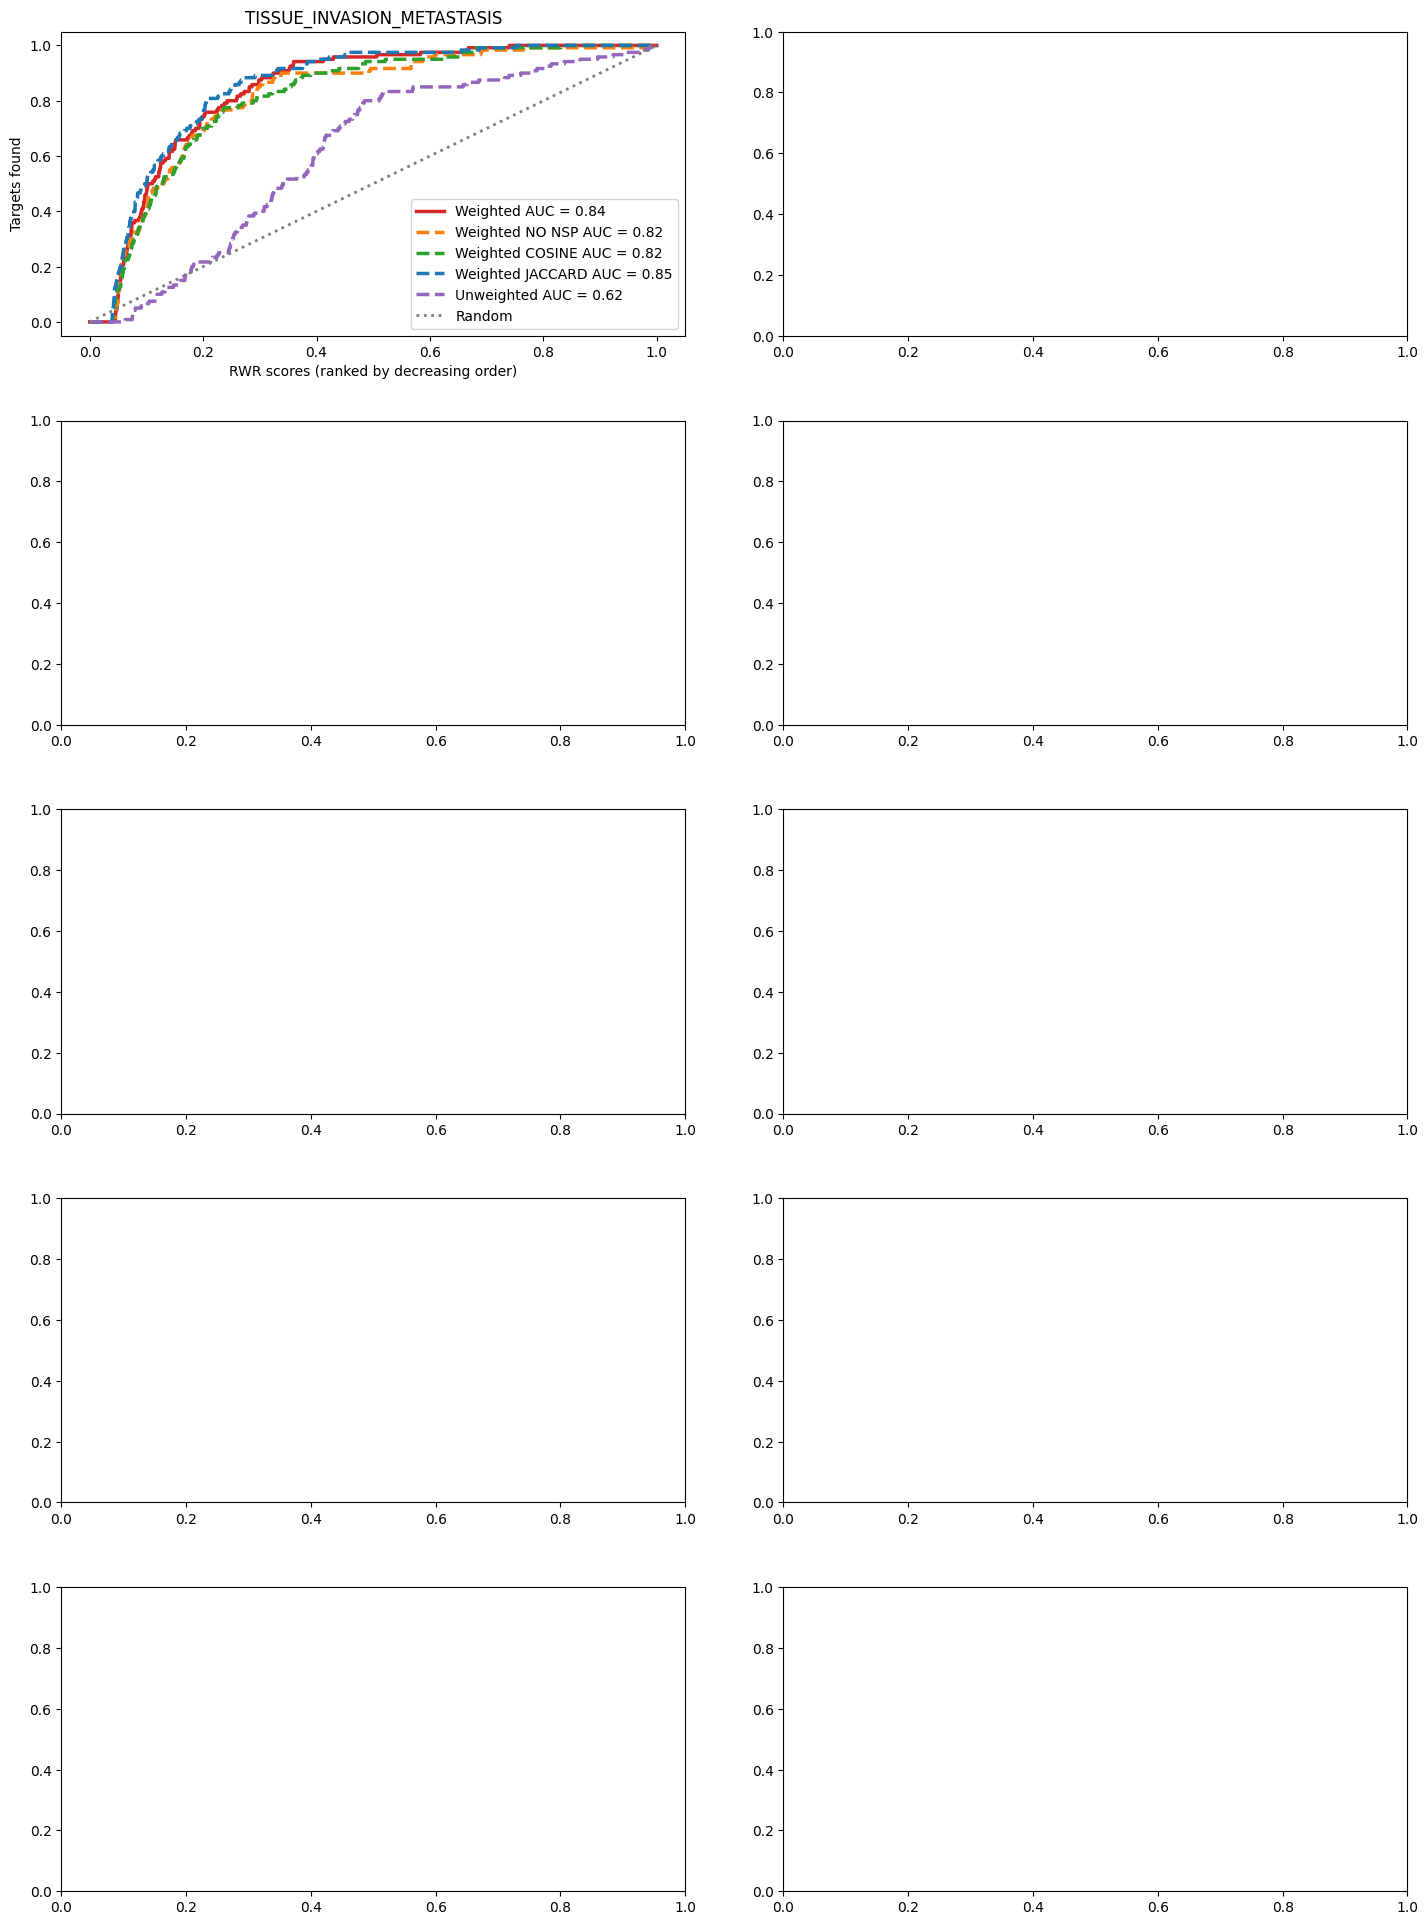

In [52]:
fig, axes = plt.subplots(nrows=5, ncols=2, figsize=(15, 20))
plt.tight_layout(pad=4.0)

for i, (hallmark_id, hallmark_name) in enumerate(dico_hallmarks_ids.items()):
    row = i // 2 
    col = i % 2

    # --- UNWEIGHTED ---
    seeds_file_unweighted = f"../../../../Results/PathwayComembership/10_ValidationRWR_bis/RWRUnweightedClique0_7/output_{hallmark_name}/{hallmark_name}_seeds.txt"
    targets_file_unweighted = f"../../../../Results/PathwayComembership/10_ValidationRWR_bis/RWRUnweightedClique0_7/output_{hallmark_name}/{hallmark_name}_targets.txt"
    scores_file_unweighted = f"../../../../Results/PathwayComembership/10_ValidationRWR_bis/RWRUnweightedClique0_7/output_{hallmark_name}/multiplex_1.tsv"

    df_scores_unweighted = pd.read_csv(scores_file_unweighted, sep='\t')
    with open(seeds_file_unweighted, 'r') as f:
        seeds = set(line.strip() for line in f if line.strip())
    with open(targets_file_unweighted, 'r') as f:
        targets = set(line.strip() for line in f if line.strip())
    df_scores_unweighted['is_target'] = df_scores_unweighted['node'].isin(targets).astype(int)
    df_scores_unweighted['is_seed'] = df_scores_unweighted['node'].isin(seeds).astype(int)
    df_scores_unweighted = df_scores_unweighted.sort_values('score', ascending=False).reset_index(drop=True)

    n_targets = df_scores_unweighted['is_target'].sum()
    n_total = len(df_scores_unweighted)
    n_non_targets = n_total - n_targets
    cumulative_targets = np.cumsum(df_scores_unweighted['is_target'].values)
    cumulative_non_targets = np.cumsum((1 - df_scores_unweighted['is_target']).values)
    positions = np.arange(len(df_scores_unweighted)) + 1
    positions_fraction = positions / len(df_scores_unweighted)
    tpr_unweighted = cumulative_targets / n_targets
    fpr_unweighted = cumulative_non_targets / n_non_targets
    auc_score_unweighted = auc(fpr_unweighted, tpr_unweighted)

    # WEIGHTED WITHOUT NSP
    seeds_file_weighted_no_nsp = f"../../../../Results/PathwayComembership/10_ValidationRWR_bis/RWRWeightedCliqueNO_NSP_0_7/output_{hallmark_name}/{hallmark_name}_seeds.txt"
    targets_file_weighted_no_nsp = f"../../../../Results/PathwayComembership/10_ValidationRWR_bis/RWRWeightedCliqueNO_NSP_0_7/output_{hallmark_name}/{hallmark_name}_targets.txt"
    scores_file_weighted_no_nsp = f"../../../../Results/PathwayComembership/10_ValidationRWR_bis/RWRWeightedCliqueNO_NSP_0_7/output_{hallmark_name}/multiplex_1.tsv"

    df_scores_weighted_no_nsp = pd.read_csv(scores_file_weighted_no_nsp, sep='\t')
    with open(seeds_file_weighted_no_nsp, 'r') as f:
        seeds = set(line.strip() for line in f if line.strip())
    with open(targets_file_weighted_no_nsp, 'r') as f:
        targets = set(line.strip() for line in f if line.strip())
    df_scores_weighted_no_nsp['is_target'] = df_scores_weighted_no_nsp['node'].isin(targets).astype(int)
    df_scores_weighted_no_nsp['is_seed'] = df_scores_weighted_no_nsp['node'].isin(seeds).astype(int)
    df_scores_weighted_no_nsp = df_scores_weighted_no_nsp.sort_values('score', ascending=False).reset_index(drop=True)

    n_targets = df_scores_weighted_no_nsp['is_target'].sum()
    n_total = len(df_scores_weighted_no_nsp)
    n_non_targets = n_total - n_targets
    cumulative_targets = np.cumsum(df_scores_weighted_no_nsp['is_target'].values)
    cumulative_non_targets = np.cumsum((1 - df_scores_weighted_no_nsp['is_target']).values)
    positions = np.arange(len(df_scores_weighted_no_nsp)) + 1
    positions_fraction = positions / len(df_scores_weighted_no_nsp)
    tpr_weighted_no_nsp = cumulative_targets / n_targets
    fpr_weighted_no_nsp = cumulative_non_targets / n_non_targets
    auc_score_weighted_no_nsp = auc(fpr_weighted_no_nsp, tpr_weighted_no_nsp)

    # WEIGHTED COSINE
    seeds_file_weighted_cosine = f"../../../../Results/PathwayComembership/10_ValidationRWR_bis/RWRWeightedClique_COSINE_0_7/output_{hallmark_name}/{hallmark_name}_seeds.txt"
    targets_file_weighted_cosine = f"../../../../Results/PathwayComembership/10_ValidationRWR_bis/RWRWeightedClique_COSINE_0_7/output_{hallmark_name}/{hallmark_name}_targets.txt"
    scores_file_weighted_cosine = f"../../../../Results/PathwayComembership/10_ValidationRWR_bis/RWRWeightedClique_COSINE_0_7/output_{hallmark_name}/multiplex_1.tsv"

    df_scores_weighted_cosine = pd.read_csv(scores_file_weighted_cosine, sep='\t')
    with open(seeds_file_weighted_cosine, 'r') as f:
        seeds = set(line.strip() for line in f if line.strip())
    with open(targets_file_weighted_cosine, 'r') as f:
        targets = set(line.strip() for line in f if line.strip())
    df_scores_weighted_cosine['is_target'] = df_scores_weighted_cosine['node'].isin(targets).astype(int)
    df_scores_weighted_cosine['is_seed'] = df_scores_weighted_cosine['node'].isin(seeds).astype(int)
    df_scores_weighted_cosine = df_scores_weighted_cosine.sort_values('score', ascending=False).reset_index(drop=True)

    n_targets = df_scores_weighted_cosine['is_target'].sum()
    n_total = len(df_scores_weighted_cosine)
    n_non_targets = n_total - n_targets
    cumulative_targets = np.cumsum(df_scores_weighted_cosine['is_target'].values)
    cumulative_non_targets = np.cumsum((1 - df_scores_weighted_cosine['is_target']).values)
    positions = np.arange(len(df_scores_weighted_cosine)) + 1
    positions_fraction = positions / len(df_scores_weighted_cosine)
    tpr_weighted_cosine = cumulative_targets / n_targets
    fpr_weighted_cosine = cumulative_non_targets / n_non_targets
    auc_score_weighted_cosine = auc(fpr_weighted_cosine, tpr_weighted_cosine)


    # WEIGHTED JACCARD
    seeds_file_weighted_jaccard = f"../../../../Results/PathwayComembership/10_ValidationRWR_bis/RWRWeightedClique_JACCARD_0_7/output_{hallmark_name}/{hallmark_name}_seeds.txt"
    targets_file_weighted_jaccard = f"../../../../Results/PathwayComembership/10_ValidationRWR_bis/RWRWeightedClique_JACCARD_0_7/output_{hallmark_name}/{hallmark_name}_targets.txt"
    scores_file_weighted_jaccard = f"../../../../Results/PathwayComembership/10_ValidationRWR_bis/RWRWeightedClique_JACCARD_0_7/output_{hallmark_name}/multiplex_1.tsv"

    df_scores_weighted_jaccard = pd.read_csv(scores_file_weighted_jaccard, sep='\t')
    with open(seeds_file_weighted_jaccard, 'r') as f:
        seeds = set(line.strip() for line in f if line.strip())
    with open(targets_file_weighted_jaccard, 'r') as f:
        targets = set(line.strip() for line in f if line.strip())
    df_scores_weighted_jaccard['is_target'] = df_scores_weighted_jaccard['node'].isin(targets).astype(int)
    df_scores_weighted_jaccard['is_seed'] = df_scores_weighted_jaccard['node'].isin(seeds).astype(int)
    df_scores_weighted_jaccard = df_scores_weighted_jaccard.sort_values('score', ascending=False).reset_index(drop=True)

    n_targets = df_scores_weighted_jaccard['is_target'].sum()
    n_total = len(df_scores_weighted_jaccard)
    n_non_targets = n_total - n_targets
    cumulative_targets = np.cumsum(df_scores_weighted_jaccard['is_target'].values)
    cumulative_non_targets = np.cumsum((1 - df_scores_weighted_jaccard['is_target']).values)
    positions = np.arange(len(df_scores_weighted_jaccard)) + 1
    positions_fraction = positions / len(df_scores_weighted_jaccard)
    tpr_weighted_jaccard = cumulative_targets / n_targets
    fpr_weighted_jaccard = cumulative_non_targets / n_non_targets
    auc_score_weighted_jaccard = auc(fpr_weighted_jaccard, tpr_weighted_jaccard)

    # --- WEIGHTED ---
    seeds_file_weighted = f"../../../../Results/PathwayComembership/10_ValidationRWR_bis/RWRWeightedClique0_7/output_{hallmark_name}/{hallmark_name}_seeds.txt"
    targets_file_weighted = f"../../../../Results/PathwayComembership/10_ValidationRWR_bis/RWRWeightedClique0_7/output_{hallmark_name}/{hallmark_name}_targets.txt"
    scores_file_weighted = f"../../../../Results/PathwayComembership/10_ValidationRWR_bis/RWRWeightedClique0_7/output_{hallmark_name}/multiplex_1.tsv"

    df_scores_weighted = pd.read_csv(scores_file_weighted, sep='\t')
    with open(seeds_file_weighted, 'r') as f:
        seeds = set(line.strip() for line in f if line.strip())
    with open(targets_file_weighted, 'r') as f:
        targets = set(line.strip() for line in f if line.strip())
    df_scores_weighted['is_target'] = df_scores_weighted['node'].isin(targets).astype(int)
    df_scores_weighted['is_seed'] = df_scores_weighted['node'].isin(seeds).astype(int)
    df_scores_weighted = df_scores_weighted.sort_values('score', ascending=False).reset_index(drop=True)

    n_targets = df_scores_weighted['is_target'].sum()
    n_total = len(df_scores_weighted)
    n_non_targets = n_total - n_targets
    cumulative_targets = np.cumsum(df_scores_weighted['is_target'].values)
    cumulative_non_targets = np.cumsum((1 - df_scores_weighted['is_target']).values)
    positions = np.arange(len(df_scores_weighted)) + 1
    positions_fraction = positions / len(df_scores_weighted)
    tpr_weighted = cumulative_targets / n_targets
    fpr_weighted = cumulative_non_targets / n_non_targets
    auc_score_weighted = auc(fpr_weighted, tpr_weighted)

    axes[row, col].plot(positions_fraction, tpr_weighted, linewidth=2.5,
    label=f'Weighted AUC = {auc_score_weighted:.2f}', color='#d62728')
    axes[row, col].plot(positions_fraction, tpr_weighted_no_nsp, '--', linewidth=2.5,
    label=f'Weighted NO NSP AUC = {auc_score_weighted_no_nsp:.2f}', color='#ff7f0e')
    axes[row, col].plot(positions_fraction, tpr_weighted_cosine, '--', linewidth=2.5,
    label=f'Weighted COSINE AUC = {auc_score_weighted_cosine:.2f}', color='#2ca02c')
    axes[row, col].plot(positions_fraction, tpr_weighted_jaccard, '--', linewidth=2.5,
    label=f'Weighted JACCARD AUC = {auc_score_weighted_jaccard:.2f}', color= '#1f77b4')
    axes[row, col].plot(positions_fraction, tpr_unweighted, '--', linewidth=2.5,
    label=f'Unweighted AUC = {auc_score_unweighted:.2f}', color='#9467bd')
    axes[row, col].plot([0, 1], [0, 1], ':', linewidth=2, label='Random', color='#7f7f7f')
    axes[row, col].set_xlabel('RWR scores (ranked by decreasing order)')
    axes[row, col].set_ylabel('Targets found')
    axes[row, col].set_title(f'{hallmark_name}')
    axes[row, col].legend(loc="lower right")
    axes[row, col].grid(False)

output_dir = "../../../../Results/PathwayComembership/10_ValidationRWR_bis/RWR_combined_ROC_07/"
os.makedirs(output_dir, exist_ok=True)
plt.savefig(f"{output_dir}/Figure6.svg", format="svg", bbox_inches="tight")
plt.savefig(f"{output_dir}/Figure6.eps", format="eps", bbox_inches="tight")
plt.show()